# Common Probability Distributions

**AI Mathematics · 3. Probability and Statistics**

Meet the discrete, continuous, and multivariate distributions that appear in likelihood models and generative methods.

> The emphasis is on short, reusable examples rather than long projects. Code examples use Python and NumPy unless noted otherwise.

## Learning objectives
- Recognize Bernoulli, Binomial, Poisson, Normal, Exponential, Beta, and Gamma distributions.
- Compute basic probabilities and moments.
- Understand the role of multivariate Gaussian models.

In [1]:
import numpy as np

## 1. Discrete distributions
- **Bernoulli(p):** a single binary outcome with mean \(p\).
- **Binomial(n,p):** successes in \(n\) independent Bernoulli trials.
- **Poisson(\lambda):** event counts in a fixed interval under a constant-rate model; its mean and variance are both \(\lambda\).

In [2]:
import math
from math import comb

p = 0.7
print("Bernoulli mean:", p)

n, k = 5, 3
print("P(Binomial(5, .7)=3):", comb(n, k) * p**k * (1-p)**(n-k))

lam = 2.0
k = 3
p_poisson = math.exp(-lam) * lam**k / math.factorial(k)
print("P(Poisson(2)=3):", p_poisson)

Bernoulli mean: 0.7
P(Binomial(5, .7)=3): 0.30870000000000003
P(Poisson(2)=3): 0.1804470443154836


## 2. Continuous distributions
- **Normal:** symmetric distribution determined by mean and variance.
- **Exponential:** waiting times in a constant-rate Poisson process.
- **Beta:** flexible distribution over probabilities in \([0,1]\).
- **Gamma:** positive-valued distribution used for waiting times and rate-related uncertainty.
A density value is not itself a probability; integrate a density over an interval to obtain probability.

In [3]:
rng = np.random.default_rng(0)
normal_samples = rng.normal(loc=2.0, scale=0.5, size=100_000)
exp_samples = rng.exponential(scale=1/2.0, size=100_000)
beta_samples = rng.beta(a=2.0, b=5.0, size=100_000)
gamma_samples = rng.gamma(shape=2.0, scale=1/3.0, size=100_000)
print("normal sample mean/std:", normal_samples.mean(), normal_samples.std())
print("exponential mean approx 1/lambda:", exp_samples.mean())
print("beta samples in [0,1]:", beta_samples.min(), beta_samples.max())
print("gamma mean approx shape*scale:", gamma_samples.mean())

normal sample mean/std: 1.9995458746134396 0.5000642520265723
exponential mean approx 1/lambda: 0.5000478123799342
beta samples in [0,1]: 0.000535245953850756 0.9246743531557133
gamma mean approx shape*scale: 0.6676369675871036


## 3. Likelihood intuition
A distribution provides a model for how data might be generated. The likelihood treats observed data as fixed and views the probability or density as a function of unknown parameters. Maximizing likelihood is a common way to fit models; the next notebook examines MLE and MAP in detail.

In [4]:
# Illustrative Gaussian negative log-likelihood, up to constants
y = np.array([1.0, 1.2, 0.8, 1.1])
mu = 1.0
sigma = 0.2
nll = np.sum(0.5*((y-mu)/sigma)**2 + np.log(sigma))
print("negative log-likelihood up to a constant:", nll)

negative log-likelihood up to a constant: -5.312751649736402


## 4. Multivariate Gaussian
A multivariate normal is described by mean vector \(\mu\) and covariance matrix \(\Sigma\). Diagonal covariance models independent coordinates; off-diagonal entries encode linear dependence. The covariance must be symmetric positive semidefinite, and a nonsingular density requires positive definiteness.

In [5]:
mean = np.array([0.0, 1.0])
cov = np.array([[1.0, 0.6], [0.6, 2.0]])
samples = rng.multivariate_normal(mean, cov, size=5000)
print("sample shape:", samples.shape)
print("empirical covariance:\n", np.cov(samples, rowvar=False))
print("covariance eigenvalues:", np.linalg.eigvalsh(cov))

sample shape: (5000, 2)
empirical covariance:
 [[1.00415025 0.59541251]
 [0.59541251 1.98383296]]
covariance eigenvalues: [0.71897503 2.28102497]


## 5. Choosing a distribution
Use a distribution whose support matches the variable: Bernoulli for binary labels, Poisson for counts, Beta for probabilities, and Normal for many continuous measurement models. Matching support is necessary but not sufficient; validate fit and assumptions against data.

### Choosing the right Python tool

- **NumPy** handles arrays, vectorized arithmetic, linear algebra, random sampling, and numerical operations.
- **pandas** is useful for named columns, tabular summaries, and experiment logs.
- **Matplotlib** gives low-level control over vector arrows, geometry, contour plots, and custom figures.
- **Seaborn** is built on Matplotlib and makes statistical plots such as heatmaps, distributions, and grouped comparisons quick to create.

Not every mathematical idea needs all four libraries. The extra examples use each tool where it clarifies the concept. Plots are diagnostic aids: always inspect axes, units, assumptions, and sample size.

## Visual lab: distributions with NumPy, pandas, and Seaborn

A probability density is not the probability at a single point; probabilities for continuous variables are areas under the density curve. Histograms approximate a distribution using samples. Comparing empirical samples with a theoretical density is a useful diagnostic, but small samples naturally fluctuate.

10_probability_distributions.ipynb:cell14:16: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


,mean,std,min,max
distribution,,,,
"Beta(2, 5)",0.285,0.160,0.004,0.861
Exponential(scale=1),0.983,0.953,0.000,7.213
"Normal(0, 1)",-0.019,1.005,-3.192,3.256


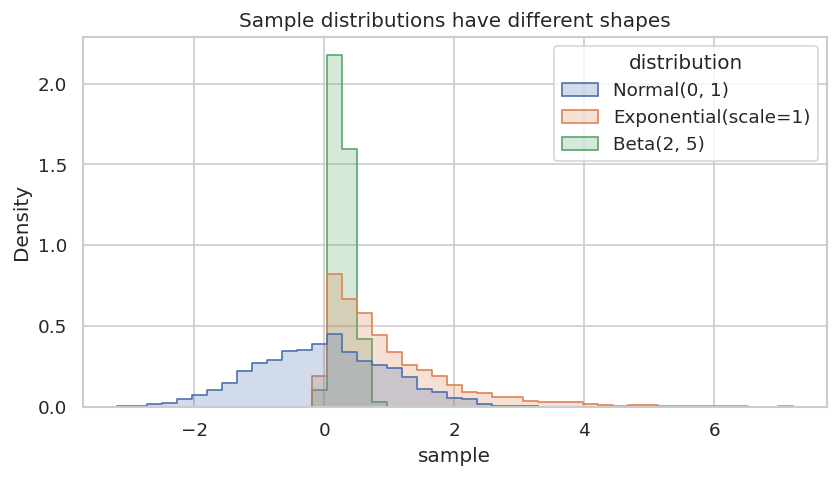

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
sns.set_theme(style="whitegrid")
viz_dist_rng = np.random.default_rng(120)
viz_dist_n = 3000
viz_dist_df = pd.DataFrame({
    "Normal(0, 1)": viz_dist_rng.normal(0, 1, viz_dist_n),
    "Exponential(scale=1)": viz_dist_rng.exponential(1, viz_dist_n),
    "Beta(2, 5)": viz_dist_rng.beta(2, 5, viz_dist_n)
}).melt(var_name="distribution", value_name="sample")
fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(data=viz_dist_df, x="sample", hue="distribution", stat="density", element="step", common_norm=False, bins=45, ax=ax)
ax.set_title("Sample distributions have different shapes"); plt.show()
display(viz_dist_df.groupby("distribution")["sample"].agg(["mean", "std", "min", "max"]).round(3))

### Plot a theoretical normal density

The normal density depends on both the mean and the standard deviation. Standardizing a variable with \((x-\mu)/\sigma\) expresses it in standard-deviation units; it does not guarantee that the transformed data are normally distributed.

10_probability_distributions.ipynb:cell16:8: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


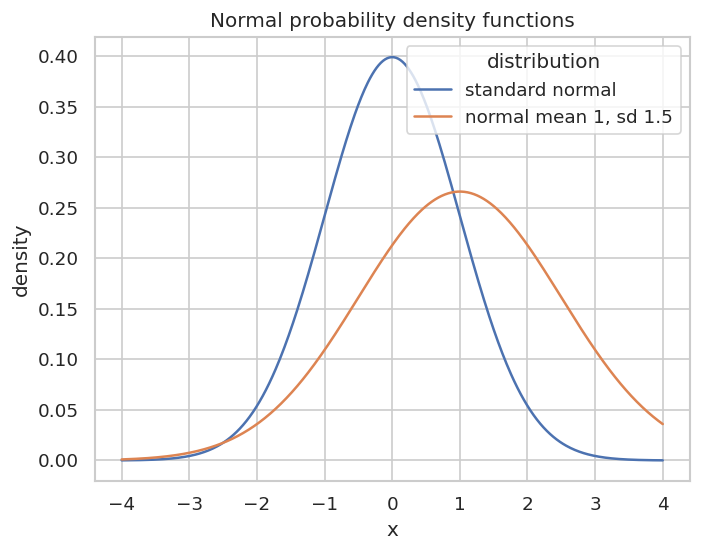

In [7]:
viz_norm_x = np.linspace(-4, 4, 500)
viz_norm_curves = pd.DataFrame({
    "x": viz_norm_x,
    "standard normal": np.exp(-0.5*viz_norm_x**2)/np.sqrt(2*np.pi),
    "normal mean 1, sd 1.5": np.exp(-0.5*((viz_norm_x-1)/1.5)**2)/(1.5*np.sqrt(2*np.pi))
}).melt(id_vars="x", var_name="distribution", value_name="density")
sns.lineplot(data=viz_norm_curves, x="x", y="density", hue="distribution")
plt.title("Normal probability density functions"); plt.show()

## Practice exercises
Try each exercise before looking at the suggested solution. These are intentionally small so you can change values and observe how the result changes.

### Exercise 1
Exercise 1: Calculate P(X=2) for X~Binomial(n=4,p=0.5).

In [8]:
from math import comb
print(comb(4, 2) * 0.5**4)

0.375


### Exercise 2
Exercise 2: Draw 1,000 samples from a Bernoulli distribution with p=0.2 and estimate its mean.

In [9]:
rng = np.random.default_rng(5)
s = rng.binomial(n=1, p=0.2, size=1000)
print(s.mean())

0.198


## Key takeaways
- Pick distributions according to the data type, support, and assumptions.
- The likelihood evaluates how compatible observed data are with candidate parameters.
- A multivariate Gaussian uses covariance to represent relationships between features.

**Next step:** Change an input, check the shapes or assumptions, and rerun the relevant cell. That habit is central to mathematical programming.